DATASET DESCRIPTION

Dataset Name: Flight Delay Dataset
Source: Hugging Face - Algo0o/flight_delay
Access: Public dataset

Description:
The dataset contains airline flight records and information about
scheduled and actual departure/arrival times, departure delays,
arrival delays, flight distance, airports, dates, and delay causes.

Important Features Used:
1. CRS_DEP_TIME - Scheduled departure time.
2. DISTANCE     - Distance between origin and destination airports.
3. FL_DATE      - Flight date, used to derive weekday and month.
4. DEP_DEL15    - Target variable: indicates whether departure
                   delay was 15 minutes or more.

Target Classes:
0 - Departure delay less than 15 minutes.
1 - Departure delay of 15 minutes or more.

Project Objective:
To develop a fuzzy logic system for flight-delay classification
and use a Genetic Algorithm to tune selected fuzzy-system
parameters. Their performance is evaluated using accuracy,
precision, recall, and F1-score.


Install libraries

In [11]:
!pip -q install datasets scikit-fuzzy scikit-learn pandas numpy matplotlib

Load the dataset

In [12]:
from datasets import load_dataset
import pandas as pd
import numpy as np

dataset = load_dataset(
    "Algo0o/flight_delay",
    split="train",
    streaming=True
)

rows = list(dataset.take(100000))
df = pd.DataFrame(rows)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Repo card metadata block was not found. Setting CardData to empty.


Dataset shape: (100000, 49)
Columns: ['airline_id', 'FL_DATE', 'OP_UNIQUE_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN_AIRPORT_ID', 'ORIGIN', 'ORIGIN_CITY_NAME', 'ORIGIN_STATE_ABR', 'ORIGIN_STATE_FIPS', 'ORIGIN_STATE_NM', 'ORIGIN_WAC', 'DEST_AIRPORT_ID', 'DEST', 'DEST_CITY_NAME', 'DEST_STATE_ABR', 'DEST_STATE_FIPS', 'DEST_STATE_NM', 'DEST_WAC', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'DEP_DELAY_NEW', 'DEP_DEL15', 'DEP_DELAY_GROUP', 'DEP_TIME_BLK', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'ARR_DEL15', 'ARR_DELAY_GROUP', 'ARR_TIME_BLK', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'FLIGHTS', 'DISTANCE', 'DISTANCE_GROUP', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY', 'DEP_DELAY_OVER15', 'ARR_DELAY_OVER15', 'TOTAL_DELAY', 'ANY_DELAY']


,airline_id,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,ORIGIN_STATE_FIPS,ORIGIN_STATE_NM,...,DISTANCE_GROUP,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,DEP_DELAY_OVER15,ARR_DELAY_OVER15,TOTAL_DELAY,ANY_DELAY
0,1,2025-07-01,AA,1,12478,JFK,New York,NY,36,New York,...,10,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0
1,2,2025-07-01,UA,2621,12266,IAH,Houston,TX,48,Texas,...,1,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0
2,3,2025-07-01,UA,2621,11278,DCA,Washington,VA,51,Virginia,...,5,0.0,21.0,0.0,0.0,9.0,1,1,30.0,1
3,4,2025-07-01,UA,2620,13486,MSO,Missoula,MT,30,Montana,...,6,0.0,0.0,29.0,0.0,0.0,0,1,29.0,1
4,5,2025-07-01,UA,2619,11292,DEN,Denver,CO,8,Colorado,...,4,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0


Clean and prepare the data

In [13]:
data = df[
    ["CRS_DEP_TIME", "DISTANCE", "FL_DATE", "DEP_DEL15"]
].copy()

data["DEP_HOUR"] = (
    pd.to_numeric(data["CRS_DEP_TIME"], errors="coerce") // 100
)

dates = pd.to_datetime(data["FL_DATE"], errors="coerce")
data["DAY_OF_WEEK"] = dates.dt.dayofweek + 1
data["MONTH"] = dates.dt.month

data = data[
    ["DEP_HOUR", "DISTANCE", "DAY_OF_WEEK", "MONTH", "DEP_DEL15"]
].copy()

for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna()
data = data[data["DEP_HOUR"].between(0, 23)]
data = data[data["DISTANCE"] > 0]
data = data[data["DAY_OF_WEEK"].between(1, 7)]
data = data[data["MONTH"].between(1, 12)]
data = data[data["DEP_DEL15"].isin([0, 1])]

data["DEP_DEL15"] = data["DEP_DEL15"].astype(int)
data = data.reset_index(drop=True)

print("Cleaned dataset:", data.shape)
print("\nClass distribution:")
print(data["DEP_DEL15"].value_counts())
display(data.head())

Cleaned dataset: (98236, 5)

Class distribution:
DEP_DEL15
0    73458
1    24778
Name: count, dtype: int64


,DEP_HOUR,DISTANCE,DAY_OF_WEEK,MONTH,DEP_DEL15
0,7,2475,2,7,0
1,20,140,2,7,0
2,16,1208,2,7,1
3,12,1332,2,7,0
4,13,846,2,7,0


Split and scale the data

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

features = ["DEP_HOUR", "DISTANCE", "DAY_OF_WEEK", "MONTH"]

X = data[features]
y = data["DEP_DEL15"]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = MinMaxScaler(feature_range=(0, 10))

X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

n_eval = min(500, len(X_test))

X_eval = X_test[:n_eval]
y_eval = y_test.iloc[:n_eval].reset_index(drop=True)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Evaluation samples:", len(X_eval))

Training samples: 78588
Testing samples: 19648
Evaluation samples: 500


Create the Fuzzy Logic system

In [15]:
import skfuzzy as fuzz
from skfuzzy import control as ctrl

hour = ctrl.Antecedent(np.arange(0, 10.1, 0.1), "hour")
distance = ctrl.Antecedent(np.arange(0, 10.1, 0.1), "distance")
weekday = ctrl.Antecedent(np.arange(0, 10.1, 0.1), "weekday")
month = ctrl.Antecedent(np.arange(0, 10.1, 0.1), "month")

risk = ctrl.Consequent(np.arange(0, 101, 1), "risk")

for variable in [hour, distance, weekday, month]:
    variable["low"] = fuzz.trimf(
        variable.universe, [0, 0, 5]
    )
    variable["medium"] = fuzz.trimf(
        variable.universe, [0, 5, 10]
    )
    variable["high"] = fuzz.trimf(
        variable.universe, [5, 10, 10]
    )

risk["low"] = fuzz.trimf(risk.universe, [0, 0, 50])
risk["high"] = fuzz.trimf(risk.universe, [50, 100, 100])

rules = [
    ctrl.Rule(hour["high"] & distance["high"], risk["high"]),
    ctrl.Rule(hour["high"] & weekday["high"], risk["high"]),
    ctrl.Rule(distance["high"] & month["high"], risk["high"]),
    ctrl.Rule(weekday["high"] & month["high"], risk["high"]),

    ctrl.Rule(hour["low"] & distance["low"], risk["low"]),
    ctrl.Rule(hour["low"] & weekday["low"], risk["low"]),
    ctrl.Rule(distance["low"] & month["low"], risk["low"]),
    ctrl.Rule(weekday["low"] & month["low"], risk["low"]),

    ctrl.Rule(
        hour["medium"] & distance["medium"],
        risk["low"]
    ),
    ctrl.Rule(
        weekday["medium"] & month["medium"],
        risk["low"]
    ),
    ctrl.Rule(hour["high"] & distance["low"], risk["low"]),
    ctrl.Rule(hour["low"] & distance["high"], risk["high"])
]

fuzzy_system = ctrl.ControlSystem(rules)

print("Fuzzy system created successfully.")
print("Number of rules:", len(rules))

Fuzzy system created successfully.
Number of rules: 12


Generate fuzzy predictions

In [16]:
def fuzzy_predict(X_values, system=fuzzy_system):
    scores = []

    for row in X_values:
        sim = ctrl.ControlSystemSimulation(system)

        sim.input["hour"] = float(row[0])
        sim.input["distance"] = float(row[1])
        sim.input["weekday"] = float(row[2])
        sim.input["month"] = float(row[3])

        try:
            sim.compute()
            scores.append(float(sim.output["risk"]))
        except (ValueError, KeyError):
            scores.append(50.0)

    return np.array(scores)


fuzzy_scores = fuzzy_predict(X_eval)

fuzzy_predictions = (
    fuzzy_scores >= 50
).astype(int)

print("Fuzzy predictions generated:", len(fuzzy_predictions))
print("First 10 predictions:", fuzzy_predictions[:10])

Fuzzy predictions generated: 500
First 10 predictions: [0 0 0 0 0 1 0 0 0 0]


Evaluate the Fuzzy Logic model

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:",
      round(accuracy_score(y_eval, fuzzy_predictions), 4))

print("Precision:",
      round(precision_score(y_eval, fuzzy_predictions, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_eval, fuzzy_predictions, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_eval, fuzzy_predictions, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_eval,
    fuzzy_predictions,
    zero_division=0
))

Accuracy: 0.716
Precision: 0.2667
Recall: 0.0296
F1-score: 0.0533

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.97      0.83       365
           1       0.27      0.03      0.05       135

    accuracy                           0.72       500
   macro avg       0.50      0.50      0.44       500
weighted avg       0.60      0.72      0.62       500



Plot the confusion matrix

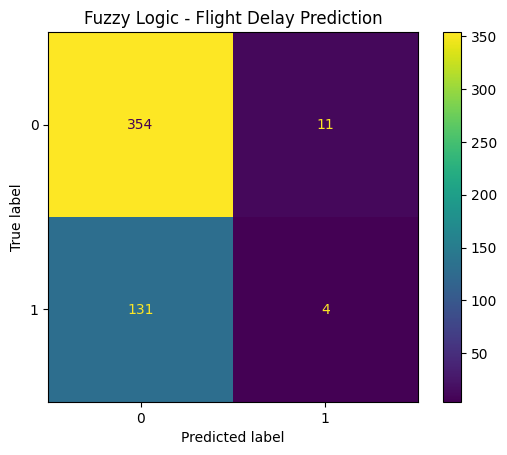

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_eval,
    fuzzy_predictions
)

plt.title("Fuzzy Logic - Flight Delay Prediction")
plt.show()

Define the Genetic Algorithm :
The Genetic Algorithm searches for a better membership-function boundary and classification threshold. It uses F1-score as the fitness measure.

In [19]:
import random
from sklearn.metrics import f1_score

random.seed(42)
np.random.seed(42)

# Small sample keeps the experiment manageable.
ga_n = min(100, len(X_train))

X_ga = X_train[:ga_n]
y_ga = y_train.iloc[:ga_n].to_numpy()


def build_system(boundary):
    h = ctrl.Antecedent(np.arange(0, 10.1, 0.1), "hour")
    d = ctrl.Antecedent(np.arange(0, 10.1, 0.1), "distance")
    w = ctrl.Antecedent(np.arange(0, 10.1, 0.1), "weekday")
    m = ctrl.Antecedent(np.arange(0, 10.1, 0.1), "month")

    r = ctrl.Consequent(np.arange(0, 101, 1), "risk")

    for variable in [h, d, w, m]:
        variable["low"] = fuzz.trimf(
            variable.universe, [0, 0, boundary]
        )
        variable["medium"] = fuzz.trimf(
            variable.universe, [0, boundary, 10]
        )
        variable["high"] = fuzz.trimf(
            variable.universe, [boundary, 10, 10]
        )

    r["low"] = fuzz.trimf(r.universe, [0, 0, 50])
    r["high"] = fuzz.trimf(r.universe, [50, 100, 100])

    rules = [
        ctrl.Rule(h["high"] & d["high"], r["high"]),
        ctrl.Rule(h["high"] & w["high"], r["high"]),
        ctrl.Rule(d["high"] & m["high"], r["high"]),
        ctrl.Rule(w["high"] & m["high"], r["high"]),
        ctrl.Rule(h["low"] & d["low"], r["low"]),
        ctrl.Rule(h["low"] & w["low"], r["low"]),
        ctrl.Rule(d["low"] & m["low"], r["low"]),
        ctrl.Rule(w["low"] & m["low"], r["low"]),
        ctrl.Rule(h["medium"] & d["medium"], r["low"]),
        ctrl.Rule(w["medium"] & m["medium"], r["low"]),
        ctrl.Rule(h["high"] & d["low"], r["low"]),
        ctrl.Rule(h["low"] & d["high"], r["high"])
    ]

    return ctrl.ControlSystem(rules)


print("Genetic Algorithm setup completed.")

Genetic Algorithm setup completed.


Run the Genetic Algorithm

In [20]:
def fitness_function(chromosome):
    boundary, threshold = chromosome

    system = build_system(boundary)

    scores = fuzzy_predict(X_ga[:30], system)
    predictions = (scores >= threshold).astype(int)

    return f1_score(
        y_ga[:30],
        predictions,
        zero_division=0
    )


# Each chromosome = [membership boundary, threshold]
population = [
    [random.uniform(3.5, 6.5), random.uniform(35, 65)]
    for _ in range(6)
]

generations = 3

for generation in range(generations):

    fitness = [
        fitness_function(individual)
        for individual in population
    ]

    ranked = [
        individual
        for _, individual in sorted(
            zip(fitness, population),
            key=lambda item: item[0],
            reverse=True
        )
    ]

    print(
        f"Generation {generation + 1}: "
        f"Best F1 = {max(fitness):.4f}"
    )

    parents = ranked[:3]
    new_population = parents.copy()

    while len(new_population) < 6:
        p1, p2 = random.choice(parents), random.choice(parents)

        child_boundary = (p1[0] + p2[0]) / 2
        child_threshold = (p1[1] + p2[1]) / 2

        child_boundary += random.uniform(-0.4, 0.4)
        child_threshold += random.uniform(-5, 5)

        child_boundary = np.clip(child_boundary, 3.5, 6.5)
        child_threshold = np.clip(child_threshold, 35, 65)

        new_population.append([
            float(child_boundary),
            float(child_threshold)
        ])

    population = new_population


final_fitness = [
    fitness_function(individual)
    for individual in population
]

best_index = int(np.argmax(final_fitness))
best_boundary, best_threshold = population[best_index]

print("\nBest membership boundary:", round(best_boundary, 3))
print("Best threshold:", round(best_threshold, 3))
print("Best validation F1:", round(final_fitness[best_index], 4))

Generation 1: Best F1 = 0.2000
Generation 2: Best F1 = 0.2000
Generation 3: Best F1 = 0.2000

Best membership boundary: 4.766
Best threshold: 35.894
Best validation F1: 0.2


In [24]:

# Generate predictions from the GA-tuned fuzzy model

ga_system = build_system(best_boundary)

ga_scores = fuzzy_predict(X_eval, ga_system)

ga_predictions = (
    ga_scores >= best_threshold
).astype(int)

print("GA predictions generated:", len(ga_predictions))
print("First 10 predictions:", ga_predictions[:10])


GA predictions generated: 500
First 10 predictions: [0 0 0 0 0 1 1 0 0 0]


Evaluate the GA-tuned model

In [28]:
ga_system = build_system(best_boundary)

ga_scores = fuzzy_predict(X_eval, ga_system)
ga_predictions = (
    ga_scores >= best_threshold
).astype(int)

print("BASELINE FUZZY MODEL")
print("F1-score:", round(
    f1_score(y_eval, fuzzy_predictions, zero_division=0), 4
))

print("\nGA-TUNED FUZZY MODEL")
print("Accuracy:", round(
    accuracy_score(y_eval, ga_predictions), 4
))
print("Precision:", round(
    precision_score(y_eval, ga_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_eval, ga_predictions, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_eval, ga_predictions, zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(
    y_eval,
    ga_predictions,
    zero_division=0
))

BASELINE FUZZY MODEL
F1-score: 0.0533

GA-TUNED FUZZY MODEL
Accuracy: 0.646
Precision: 0.2614
Recall: 0.1704
F1-score: 0.2063

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.82      0.77       365
           1       0.26      0.17      0.21       135

    accuracy                           0.65       500
   macro avg       0.49      0.50      0.49       500
weighted avg       0.60      0.65      0.62       500



Compare both models

,Model,Accuracy,Precision,Recall,F1-score
0,Fuzzy Logic,0.716,0.2667,0.0296,0.0533
1,GA-Tuned Fuzzy Logic,0.646,0.2614,0.1704,0.2063


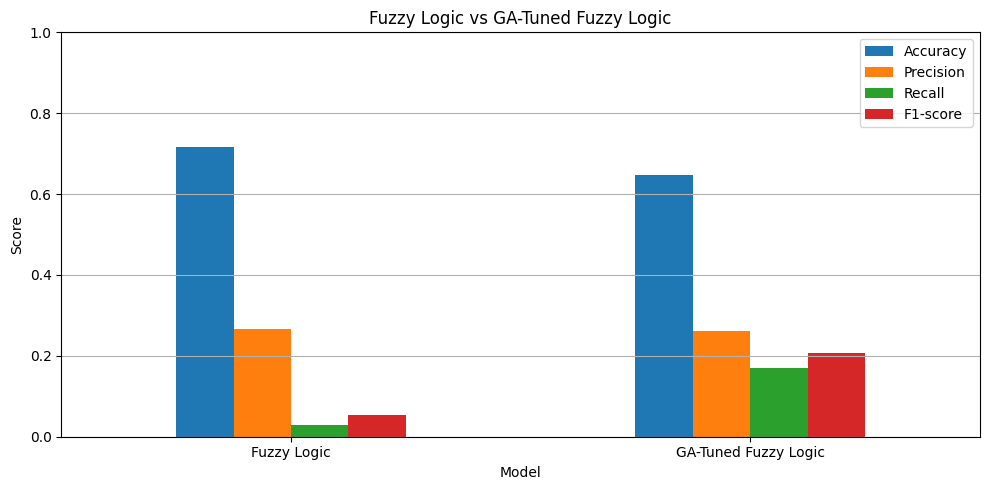

In [25]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    "Model": ["Fuzzy Logic", "GA-Tuned Fuzzy Logic"],
    "Accuracy": [
        accuracy_score(y_eval, fuzzy_predictions),
        accuracy_score(y_eval, ga_predictions)
    ],
    "Precision": [
        precision_score(y_eval, fuzzy_predictions, zero_division=0),
        precision_score(y_eval, ga_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_eval, fuzzy_predictions, zero_division=0),
        recall_score(y_eval, ga_predictions, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_eval, fuzzy_predictions, zero_division=0),
        f1_score(y_eval, ga_predictions, zero_division=0)
    ]
})

display(comparison.round(4))

comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Fuzzy Logic vs GA-Tuned Fuzzy Logic")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


Predict a sample flight

In [26]:
# Example: 6 PM departure, 900-mile flight, Tuesday, July.
sample = pd.DataFrame({
    "DEP_HOUR": [18],
    "DISTANCE": [900],
    "DAY_OF_WEEK": [2],
    "MONTH": [7]
})

sample_scaled = scaler.transform(sample[features])

sample_score = fuzzy_predict(
    sample_scaled,
    ga_system
)[0]

prediction = (
    "Likely delayed by 15+ minutes"
    if sample_score >= best_threshold
    else "Likely not delayed by 15+ minutes"
)

print("Fuzzy risk score:", round(sample_score, 2), "/ 100")
print("Prediction:", prediction)

Fuzzy risk score: 16.67 / 100
Prediction: Likely not delayed by 15+ minutes
